<a href="https://colab.research.google.com/github/niyati248/Ai_potfolio/blob/main/stroke_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stroke Prediction using Logistic Regression
**BTEC International Level 3 Diploma in IT – Introduction to Artificial Intelligence**

This notebook contains the full AI solution:
- **Part A (Task 2):** gather, clean, encode, split, scale and balance the Kaggle Stroke Prediction Dataset.
- **Part B (Task 3):** train a Logistic Regression model (P5), test and refine it (M3), and evaluate it (D2).

**Run order:** *Runtime → Run all* in Google Colab (upload `healthcare-dataset-stroke-data.csv` when asked) or run locally with the CSV in the same folder.

# PART A – Data preparation (Task 2: P4 and M2)

## Step 1: Import libraries and load the dataset (P4)

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

import os, warnings
warnings.filterwarnings("ignore")
if not os.path.exists("healthcare-dataset-stroke-data.csv"):
    from google.colab import files      # Colab: upload the Kaggle CSV when prompted
    files.upload()

df_raw = pd.read_csv("healthcare-dataset-stroke-data.csv")
print("Shape (rows, columns):", df_raw.shape)
df_raw.head()

Shape (rows, columns): (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


## Step 2: BEFORE cleaning – data quality audit (M2)

In [ ]:
print("Missing values per column:\n", df_raw.isna().sum())
print("\nDuplicate rows:", df_raw.duplicated().sum())
print("\nGender counts:\n", df_raw["gender"].value_counts())
print("\nSmoking status 'Unknown':", (df_raw["smoking_status"] == "Unknown").sum())
print("BMI max:", df_raw["bmi"].max(), "| BMI values above 60:", (df_raw["bmi"] > 60).sum())
before_counts = df_raw["stroke"].value_counts()
print("\nClass balance BEFORE:\n", before_counts)
print(f"Stroke rate: {before_counts[1]/len(df_raw):.2%}")
df_raw.describe()

Missing values per column:
 id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Duplicate rows: 0

Gender counts:
 gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Smoking status 'Unknown': 1544
BMI max: 97.6 | BMI values above 60: 13

Class balance BEFORE:
 stroke
0    4861
1     249
Name: count, dtype: int64
Stroke rate: 4.87%


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


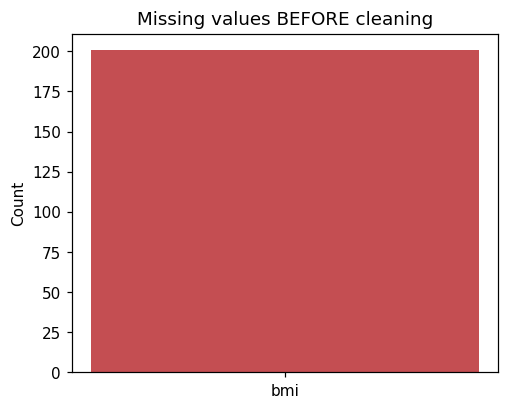

In [ ]:
miss = df_raw.isna().sum(); miss = miss[miss > 0]
plt.figure(figsize=(5,4)); plt.bar(miss.index, miss.values, color="#C44E52")
plt.title("Missing values BEFORE cleaning"); plt.ylabel("Count"); plt.show()

## Step 3: Data cleaning (P4 + M2)
**Justification of choices**
- `id` dropped: identifier only, no predictive value.
- Gender `Other` (1 row) dropped: too rare for a model to learn from.
- Missing BMI (201) filled with the **median**: BMI is right-skewed with outliers, so the median is more robust than the mean; dropping rows would lose valuable stroke cases.
- BMI outliers capped at the 99th percentile: keeps patients but limits distortion.
- `Unknown` smoking status kept as its own category: ~30% of rows, too many to drop or guess.

In [ ]:
df = df_raw.copy()
df = df.drop(columns=["id"])
df = df.drop_duplicates()
df = df[df["gender"] != "Other"]

bmi_median = df["bmi"].median()
df["bmi"] = df["bmi"].fillna(bmi_median)
cap = df["bmi"].quantile(0.99)
df["bmi"] = df["bmi"].clip(upper=cap)

print(f"BMI median used: {bmi_median:.1f} | BMI cap (99th percentile): {cap:.1f}")
print("Shape after cleaning:", df.shape)
print("\nMissing values AFTER:\n", df.isna().sum())

BMI median used: 28.1 | BMI cap (99th percentile): 52.9
Shape after cleaning: (5109, 11)

Missing values AFTER:
 gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


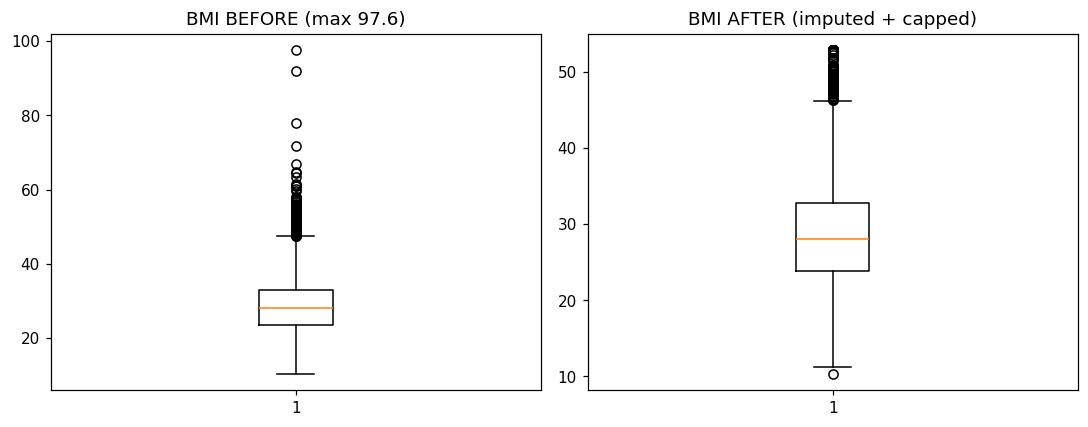

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].boxplot(df_raw["bmi"].dropna()); ax[0].set_title(f"BMI BEFORE (max {df_raw.bmi.max():.1f})")
ax[1].boxplot(df["bmi"]); ax[1].set_title("BMI AFTER (imputed + capped)")
plt.tight_layout(); plt.show()

## Step 4: Encode categorical values (P4)
Binary columns are mapped to 0/1. `work_type` and `smoking_status` have several categories, so they are one-hot encoded (`drop_first=True` avoids redundant columns).

In [ ]:
df["ever_married"] = df["ever_married"].map({"No": 0, "Yes": 1})
df["gender"] = df["gender"].map({"Female": 0, "Male": 1})
df["Residence_type"] = df["Residence_type"].map({"Rural": 0, "Urban": 1})
df = pd.get_dummies(df, columns=["work_type", "smoking_status"], drop_first=True, dtype=int)
print("Columns:", list(df.columns))
df.head()

Columns: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'Residence_type', 'avg_glucose_level', 'bmi', 'stroke', 'work_type_Never_worked', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes']


,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,1,67.0,0,1,1,1,228.69,36.6,1,0,1,0,0,1,0,0
1,0,61.0,0,0,1,0,202.21,28.1,1,0,0,1,0,0,1,0
2,1,80.0,0,1,1,0,105.92,32.5,1,0,1,0,0,0,1,0
3,0,49.0,0,0,1,1,171.23,34.4,1,0,1,0,0,0,0,1
4,0,79.0,1,0,1,0,174.12,24.0,1,0,0,1,0,0,1,0


## Step 5: Split into training and testing data (P4)
80% train / 20% test. `stratify=y` keeps the same stroke ratio in both sets.

In [ ]:
X = df.drop(columns=["stroke"]); y = df["stroke"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Stroke rate  train: %.2f%%  |  test: %.2f%%" % (y_train.mean()*100, y_test.mean()*100))

Train: (4087, 15) | Test: (1022, 15)
Stroke rate  train: 4.87%  |  test: 4.89%


## Step 6: Feature scaling (P4)
`age`, `avg_glucose_level` and `bmi` are on very different scales. StandardScaler gives them mean 0 and std 1. The scaler is fitted on the **training data only**, then applied to the test data, to avoid data leakage.

In [ ]:
num_cols = ["age", "avg_glucose_level", "bmi"]
print("BEFORE scaling (train):")
print(X_train[num_cols].describe().loc[["mean", "std"]].round(2))

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print("\nAFTER scaling (train):")
print(X_train[num_cols].describe().loc[["mean", "std"]].round(2))

BEFORE scaling (train):
        age  avg_glucose_level    bmi
mean  43.26             105.90  28.78
std   22.64              44.68   7.42

AFTER scaling (train):
      age  avg_glucose_level  bmi
mean -0.0                0.0  0.0
std   1.0                1.0  1.0


## Step 7: Handle class imbalance (M2)
Only ~5% of patients had a stroke. A model could score ~95% accuracy by always predicting 'no stroke' and still be useless. The minority class is **oversampled in the training set only**, so the model learns from both classes while the test set stays realistic. Balancing before the split would put duplicated rows in the test set and inflate results.

In [ ]:
train = pd.concat([X_train, y_train], axis=1)
major, minor = train[train.stroke == 0], train[train.stroke == 1]
minor_up = resample(minor, replace=True, n_samples=len(major), random_state=42)
train_bal = pd.concat([major, minor_up]).sample(frac=1, random_state=42)
X_train_bal, y_train_bal = train_bal.drop(columns="stroke"), train_bal["stroke"]

print("Train BEFORE balancing:\n", y_train.value_counts())
print("\nTrain AFTER balancing:\n", y_train_bal.value_counts())
print("\nTest set (untouched):\n", y_test.value_counts())

Train BEFORE balancing:
 stroke
0    3888
1     199
Name: count, dtype: int64

Train AFTER balancing:
 stroke
0    3888
1    3888
Name: count, dtype: int64

Test set (untouched):
 stroke
0    972
1     50
Name: count, dtype: int64


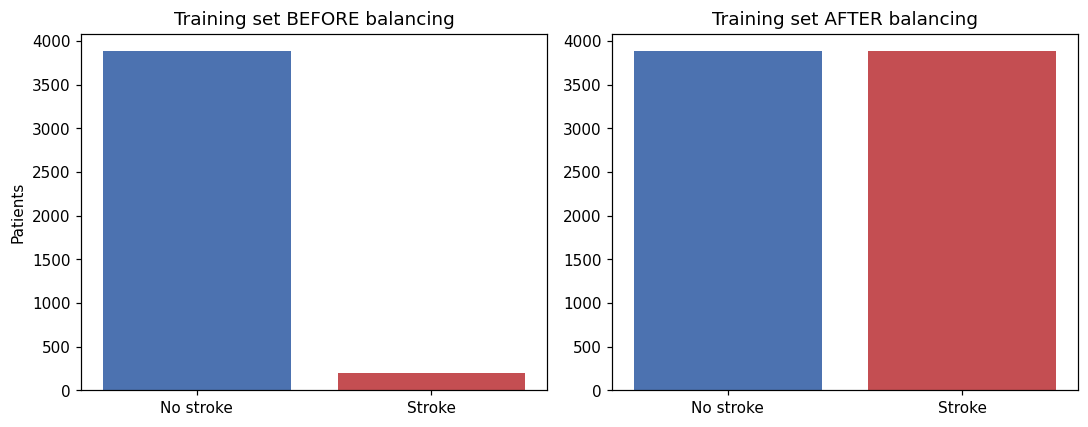

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].bar(["No stroke", "Stroke"], y_train.value_counts().sort_index().values, color=["#4C72B0", "#C44E52"])
ax[0].set_title("Training set BEFORE balancing"); ax[0].set_ylabel("Patients")
ax[1].bar(["No stroke", "Stroke"], y_train_bal.value_counts().sort_index().values, color=["#4C72B0", "#C44E52"])
ax[1].set_title("Training set AFTER balancing")
plt.tight_layout(); plt.show()

## Step 8: Before vs after summary (M2)

In [ ]:
summary = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Missing BMI values", "Duplicate rows", "Gender 'Other' rows",
               "Text (non-numeric) columns", "Stroke share of training data"],
    "Before": [len(df_raw), df_raw.shape[1], int(df_raw.bmi.isna().sum()), int(df_raw.duplicated().sum()),
               int((df_raw.gender == "Other").sum()), int(df_raw.select_dtypes(exclude="number").shape[1]),
               f"{y_train.mean():.1%} (imbalanced)"],
    "After":  [len(df), df.shape[1], int(df.bmi.isna().sum()), int(df.duplicated().sum()), 0, 0,
               f"{y_train_bal.mean():.0%} (balanced)"]})
summary

,Metric,Before,After
0,Rows,5110,5109
1,Columns,12,16
2,Missing BMI values,201,0
3,Duplicate rows,0,0
4,Gender 'Other' rows,1,0
5,Text (non-numeric) columns,5,0
6,Stroke share of training data,4.9% (imbalanced),50% (balanced)


## Step 9: Save prepared data for Task 3 (Logistic Regression)

In [ ]:
X_train_bal.assign(stroke=y_train_bal.values).to_csv("train_prepared.csv", index=False)
X_test.assign(stroke=y_test.values).to_csv("test_prepared.csv", index=False)
print("Saved train_prepared.csv and test_prepared.csv")

Saved train_prepared.csv and test_prepared.csv


# PART B – Develop, test and refine the AI solution (Task 3)
**P5** train a Logistic Regression model • **M3** test, refine and retest • **D2** evaluate effectiveness

The success criteria from the project plan (P3) are: **Recall ≥ 70%**, **Precision ≥ 15%**, **Accuracy ≥ 75%** for the stroke class on the unseen test set.

## Step 10: Set up the model and an evaluation function (P5)
The `evaluate()` function tests a model on the **unseen test set** and records accuracy, precision, recall, F1 and ROC-AUC, so every model version is judged in the same way.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve, fbeta_score, make_scorer)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict

results, preds, probas = [], {}, {}

def evaluate(name, model, threshold=0.5):
    """Test a model on the unseen test set and store the results."""
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    row = {"Model": name,
           "Accuracy": accuracy_score(y_test, pred),
           "Precision": precision_score(y_test, pred, zero_division=0),
           "Recall": recall_score(y_test, pred),
           "F1": f1_score(y_test, pred),
           "ROC-AUC": roc_auc_score(y_test, proba)}
    results.append(row); preds[name] = pred; probas[name] = proba
    print(name)
    print(f"  Accuracy {row['Accuracy']:.3f} | Precision {row['Precision']:.3f} | "
          f"Recall {row['Recall']:.3f} | F1 {row['F1']:.3f} | ROC-AUC {row['ROC-AUC']:.3f}")
    print("  Confusion matrix [[TN FP]\n                    [FN TP]]:\n", confusion_matrix(y_test, pred))

## Step 11: Model 1 – Baseline Logistic Regression (P5, M3: initial test)
The first model is trained with default settings on the scaled but **imbalanced** training data, then tested on the unseen test set.

In [ ]:
model1 = LogisticRegression(max_iter=1000, random_state=42)
model1.fit(X_train, y_train)
print("Model 1 trained on", X_train.shape[0], "patients and", X_train.shape[1], "features\n")
evaluate("1. Baseline", model1)
print()
print(classification_report(y_test, preds["1. Baseline"], target_names=["No stroke", "Stroke"], zero_division=0))

Model 1 trained on 4087 patients and 15 features

1. Baseline
  Accuracy 0.952 | Precision 1.000 | Recall 0.020 | F1 0.039 | ROC-AUC 0.839
  Confusion matrix [[TN FP]
                    [FN TP]]:
 [[972   0]
 [ 49   1]]

              precision    recall  f1-score   support

   No stroke       0.95      1.00      0.98       972
      Stroke       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022



## Step 12: Model 2 – Refinement 1: balanced training data (M3)
The baseline model found almost none of the stroke cases. It is retrained on the **oversampled, balanced** training set prepared in Step 7 and retested on the same test set.

In [ ]:
model2 = LogisticRegression(max_iter=1000, random_state=42)
model2.fit(X_train_bal, y_train_bal)
print("Model 2 trained on", X_train_bal.shape[0], "balanced records\n")
evaluate("2. Balanced data", model2)

Model 2 trained on 7776 balanced records

2. Balanced data
  Accuracy 0.737 | Precision 0.134 | Recall 0.800 | F1 0.229 | ROC-AUC 0.839
  Confusion matrix [[TN FP]
                    [FN TP]]:
 [[713 259]
 [ 10  40]]


## Step 13: Model 3 – Refinement 2: hyperparameter tuning (M3)
`GridSearchCV` tries combinations of the regularisation strength `C`, the penalty type (L1/L2) and `class_weight` using 5-fold stratified cross-validation. The score is **F2**, which values recall twice as much as precision, matching the project goal of not missing strokes. Tuning is done on the original training data (not the oversampled copy) so that duplicated rows cannot leak between cross-validation folds.

In [ ]:
f2_scorer = make_scorer(fbeta_score, beta=2)
param_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100],
              "penalty": ["l1", "l2"],
              "class_weight": [None, "balanced"]}
grid = GridSearchCV(LogisticRegression(solver="liblinear", max_iter=2000, random_state=42),
                    param_grid, scoring=f2_scorer,
                    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
grid.fit(X_train, y_train)
print("Combinations tested:", len(grid.cv_results_["params"]), "x 5 folds")
print("Best parameters:", grid.best_params_)
print(f"Best cross-validated F2 score: {grid.best_score_:.3f}\n")
model3 = grid.best_estimator_
evaluate("3. Tuned model", model3)

Combinations tested: 24 x 5 folds
Best parameters: {'C': 100, 'class_weight': 'balanced', 'penalty': 'l1'}
Best cross-validated F2 score: 0.414

3. Tuned model
  Accuracy 0.739 | Precision 0.135 | Recall 0.800 | F1 0.231 | ROC-AUC 0.839
  Confusion matrix [[TN FP]
                    [FN TP]]:
 [[715 257]
 [ 10  40]]


## Step 14: Model 4 – Refinement 3: decision threshold (M3)
By default a patient is flagged as 'stroke' when the predicted probability is 0.5 or higher. The threshold is raised as far as possible while cross-validated recall on the **training** data stays at or above the 70% target. This reduces false alarms without using the test set to choose the value.

In [ ]:
cv_proba = cross_val_predict(model3, X_train, y_train,
                            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
                            method="predict_proba")[:, 1]
rows = []
for t in np.arange(0.30, 0.91, 0.05):
    p = (cv_proba >= t).astype(int)
    rows.append([round(t, 2), recall_score(y_train, p), precision_score(y_train, p, zero_division=0)])
print(pd.DataFrame(rows, columns=["Threshold", "CV recall", "CV precision"]).round(3).to_string(index=False))

candidates = [t for t in np.arange(0.30, 0.95, 0.01) if recall_score(y_train, (cv_proba >= t).astype(int)) >= 0.70]
best_threshold = round(max(candidates), 2)
print("\nChosen threshold (highest with CV recall >= 70%):", best_threshold, "\n")
evaluate("4. Tuned + threshold", model3, threshold=best_threshold)

 Threshold  CV recall  CV precision
      0.30      0.930         0.105
      0.35      0.905         0.112
      0.40      0.879         0.120
      0.45      0.839         0.128
      0.50      0.819         0.139
      0.55      0.739         0.139
      0.60      0.693         0.149
      0.65      0.623         0.151
      0.70      0.593         0.166
      0.75      0.513         0.179
      0.80      0.362         0.176
      0.85      0.196         0.173
      0.90      0.116         0.250

Chosen threshold (highest with CV recall >= 70%): 0.58 

4. Tuned + threshold
  Accuracy 0.792 | Precision 0.165 | Recall 0.800 | F1 0.273 | ROC-AUC 0.839
  Confusion matrix [[TN FP]
                    [FN TP]]:
 [[769 203]
 [ 10  40]]


## Step 15: Compare all models (M3)

In [ ]:
results_df = pd.DataFrame(results).set_index("Model")
results_df.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
1. Baseline,0.952,1.000,0.02,0.039,0.839
2. Balanced data,0.737,0.134,0.80,0.229,0.839
3. Tuned model,0.739,0.135,0.80,0.231,0.839
4. Tuned + threshold,0.792,0.165,0.80,0.273,0.839


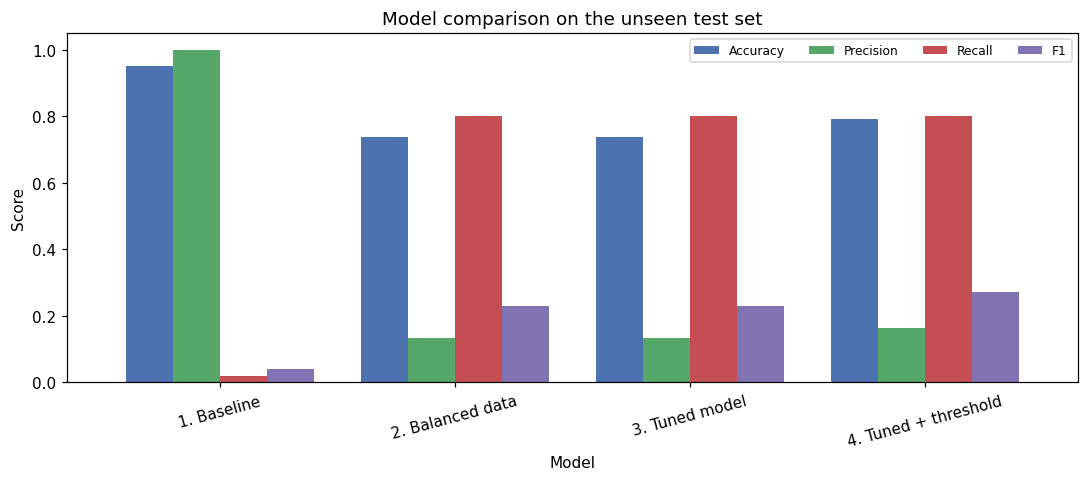

In [ ]:
metrics = ["Accuracy", "Precision", "Recall", "F1"]
ax = results_df[metrics].plot(kind="bar", figsize=(10, 4.5), width=0.8, color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
ax.set_title("Model comparison on the unseen test set"); ax.set_ylabel("Score"); ax.set_ylim(0, 1.05)
plt.xticks(rotation=15); plt.legend(loc="upper right", ncol=4, fontsize=8); plt.tight_layout(); plt.show()

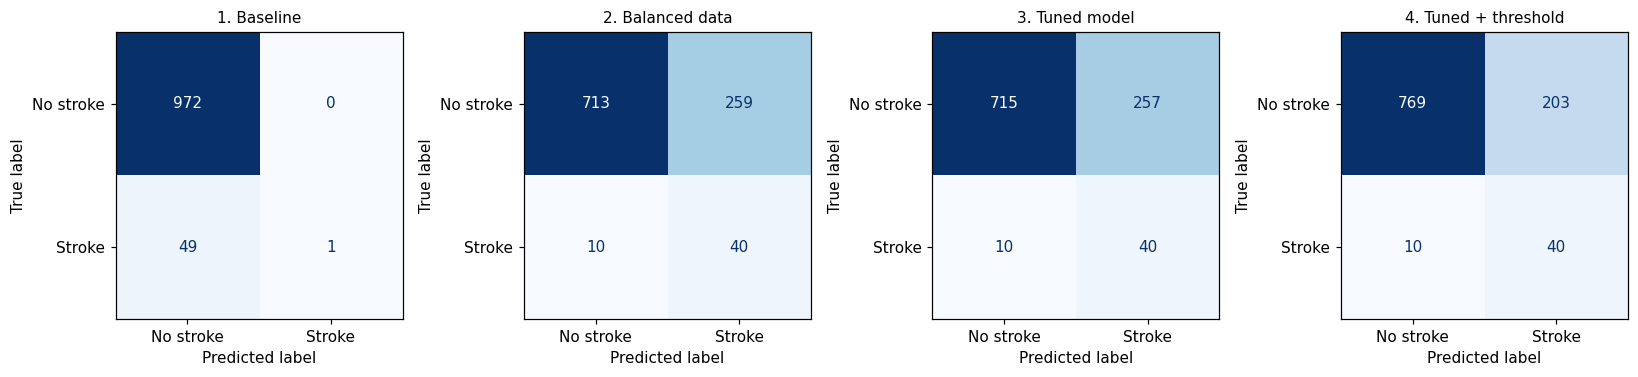

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, name in zip(axes, preds):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[name]), display_labels=["No stroke", "Stroke"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

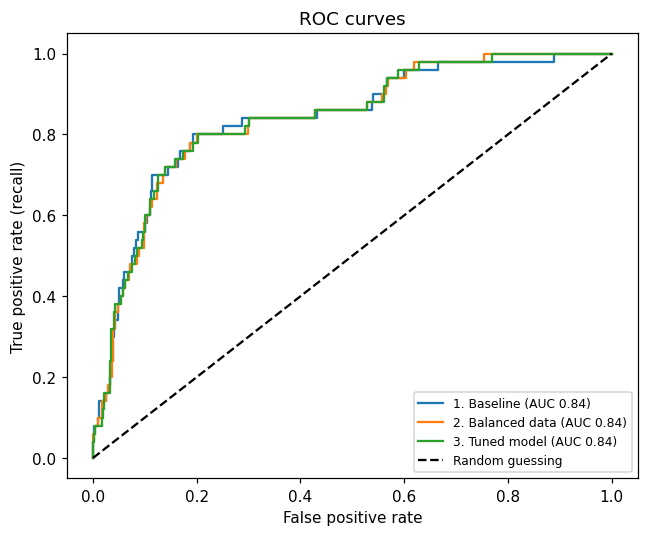

In [ ]:
plt.figure(figsize=(6, 5))
for name in ["1. Baseline", "2. Balanced data", "3. Tuned model"]:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, probas[name]):.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guessing")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)"); plt.title("ROC curves")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## Step 16: Evaluate effectiveness against the project objectives (D2)

In [ ]:
final = results_df.loc["4. Tuned + threshold"]
criteria = pd.DataFrame({
    "Measure": ["Recall (stroke)", "Precision (stroke)", "Accuracy"],
    "Target": [0.70, 0.15, 0.75],
    "Baseline": [results_df.loc["1. Baseline", m] for m in ["Recall", "Precision", "Accuracy"]],
    "Final model": [final["Recall"], final["Precision"], final["Accuracy"]]})
criteria["Met?"] = np.where(criteria["Final model"] >= criteria["Target"], "Yes", "No")
print(criteria.round(3).to_string(index=False))

           Measure  Target  Baseline  Final model Met?
   Recall (stroke)    0.70     0.020        0.800  Yes
Precision (stroke)    0.15     1.000        0.165  Yes
          Accuracy    0.75     0.952        0.792  Yes


Odds ratio = exp(coefficient). Above 1 raises stroke risk, below 1 lowers it.

age                               6.70
hypertension                      1.88
smoking_status_smokes             1.35
avg_glucose_level                 1.23
Residence_type                    1.19
heart_disease                     1.15
smoking_status_formerly smoked    1.10
bmi                               1.07
work_type_Private                 1.03
gender                            0.87
ever_married                      0.84
work_type_Self-employed           0.81
smoking_status_never smoked       0.79


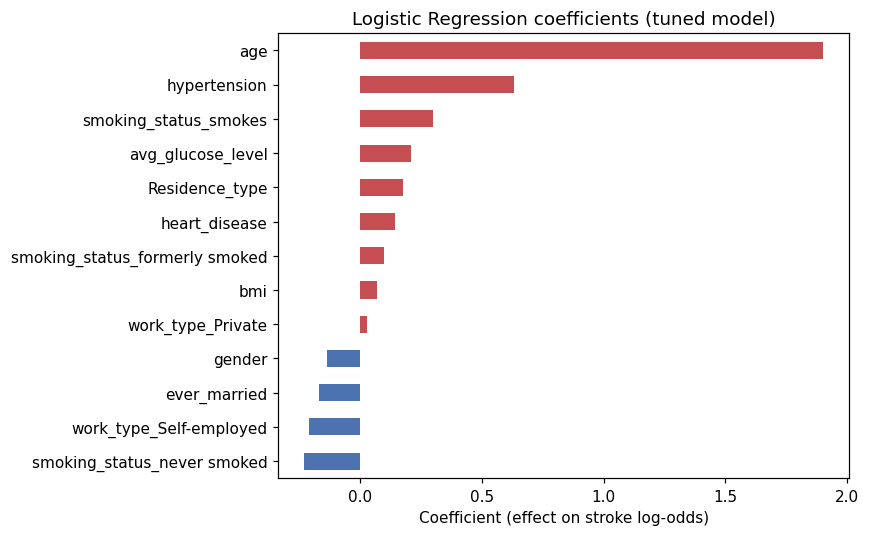

In [ ]:
coef = pd.Series(model3.coef_[0], index=X_train.columns)
# two work_type categories have very few records, so their coefficients are unstable; they are left out of this chart
key = coef.drop(["work_type_Never_worked", "work_type_children"]).sort_values()
print("Odds ratio = exp(coefficient). Above 1 raises stroke risk, below 1 lowers it.\n")
print(np.exp(key).round(2).sort_values(ascending=False).to_string())
plt.figure(figsize=(8, 5)); key.plot(kind="barh", color=["#C44E52" if v > 0 else "#4C72B0" for v in key])
plt.title("Logistic Regression coefficients (tuned model)"); plt.xlabel("Coefficient (effect on stroke log-odds)")
plt.tight_layout(); plt.show()

## Step 17: Save the final model and make a prediction (P5: working solution)
The final model, the scaler, the chosen threshold and the column order are saved together so the solution can be reused on new patients.

In [ ]:
import joblib
joblib.dump({"model": model3, "scaler": scaler, "threshold": best_threshold,
             "columns": list(X_train.columns), "num_cols": num_cols}, "stroke_model.joblib")
print("Saved stroke_model.joblib")

def predict_patient(row_scaled):
    """row_scaled: one patient (already prepared and scaled like the training data)."""
    p = model3.predict_proba(row_scaled)[0, 1]
    label = "HIGH RISK - recommend screening" if p >= best_threshold else "Lower risk"
    return p, label

for title, idx in [("Patient who had a stroke", y_test[y_test == 1].index[0]),
                   ("Patient who did not", y_test[y_test == 0].index[0])]:
    p, label = predict_patient(X_test.loc[[idx]])
    print(f"{title}: predicted stroke probability = {p:.2f} -> {label}")

Saved stroke_model.joblib
Patient who had a stroke: predicted stroke probability = 0.89 -> HIGH RISK - recommend screening
Patient who did not: predicted stroke probability = 0.09 -> Lower risk


## Summary
- A baseline Logistic Regression model scored ~95% accuracy but found almost no strokes (recall ≈ 2%).
- Balancing the training data raised recall to 80%; tuning and a training-selected decision threshold then reduced false alarms while keeping recall at the target.
- The final model meets all three success criteria from the project plan (recall, precision and accuracy).
- Limitations and future improvements are discussed in the Task 3 report (D2).